# 01 · WM-811K exploratory analysis

**Goal:** understand the wafer-map data before building a defect-pattern classifier, and check whether defect patterns relate to die yield (the link used in step 4).

**Questions**
1. How many wafers are labeled, and how imbalanced are the 9 classes?
2. How much do map sizes vary? (affects CNN input design)
3. What does each defect pattern look like?
4. Does die yield differ by defect pattern?

In [3]:
%matplotlib inline
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path

from wafer import eda
from wafer.data import load_secom, load_wm811k

FIG_DIR = Path("../reports/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.precision", 3)

In [4]:
df = load_wm811k()
print(f'{len(df):,} wafers')
df.head()

811,457 wafers


,wafer_map,die_size,lot,wafer_index,split,failure_type,rows,cols,n_dies,n_fail,die_yield,is_labeled
0,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,1,Training,none,45,48,1683,88,0.948,True
1,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,2,Training,none,45,48,1683,86,0.949,True
2,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,3,Training,none,45,48,1683,66,0.961,True
3,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,4,Training,none,45,48,1683,104,0.938,True
4,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,...",1683.0,lot1,5,Training,none,45,48,1683,71,0.958,True


## 1. Labeled vs unlabeled, and class imbalance

In [5]:
print(df['is_labeled'].value_counts(normalize=True).rename('share'))
summary = eda.label_summary(df)
summary

is_labeled
False    0.787
True     0.213
Name: share, dtype: float64


,count,share,imbalance_vs_largest
failure_type,,,
Center,4294,2.483e-02,34.334
Donut,555,3.209e-03,265.641
Edge-Loc,5189,3.000e-02,28.412
Edge-Ring,9680,5.597e-02,15.230
Loc,3593,2.077e-02,41.033
Near-full,149,8.615e-04,989.470
Random,866,5.007e-03,170.244
Scratch,1193,6.898e-03,123.580
none,147431,8.524e-01,1.000


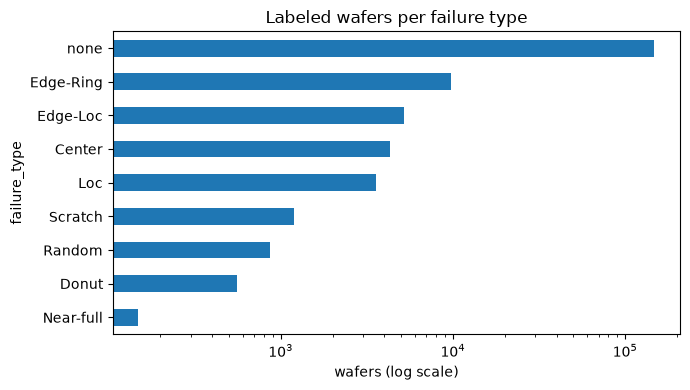

In [6]:
ax = summary['count'].sort_values().plot.barh(figsize=(7, 4), logx=True)
ax.set_xlabel('wafers (log scale)')
ax.set_title('Labeled wafers per failure type')
plt.tight_layout(); plt.savefig(FIG_DIR / 'wm811k_class_counts.png', dpi=150)

> **Why it matters:** with `none` dominating, accuracy is misleading. Models will be compared on **macro-F1** and per-class recall, and training will use class weights / augmentation for rare classes such as `Near-full` and `Donut`.

## 2. Wafer map sizes

In [7]:
shape_counts = df.groupby(['rows', 'cols']).size().sort_values(ascending=False)
print(f'{len(shape_counts)} distinct map shapes')
shape_counts.head(10)

632 distinct map shapes


rows  cols
32    29      108687
25    27       64083
49    39       39323
26    26       30078
30    34       29513
33    33       23886
      29       20276
39    37       15327
52    59       14812
31    31       14569
dtype: int64

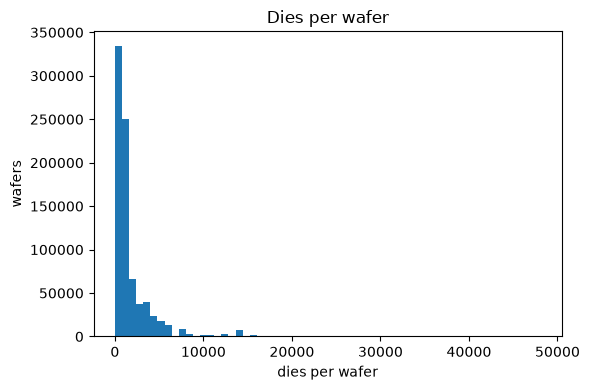

In [8]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(df['n_dies'], bins=60)
ax.set_xlabel('dies per wafer'); ax.set_ylabel('wafers')
ax.set_title('Dies per wafer'); plt.tight_layout()

> **Why it matters:** maps come in many shapes, so the CNN needs a fixed input (resize to e.g. 64x64 with nearest-neighbour to keep die states discrete).

## 3. What each defect pattern looks like

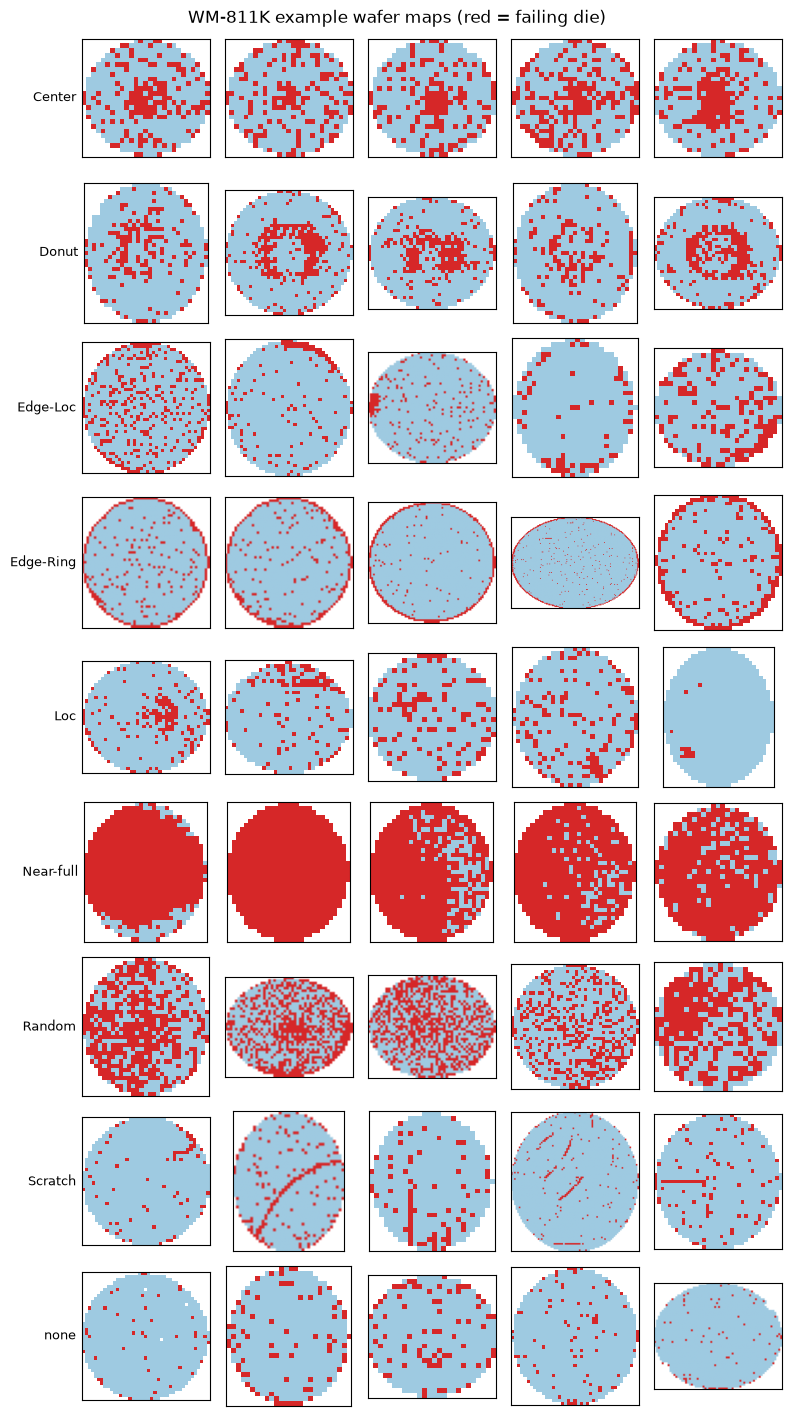

In [9]:
fig = eda.plot_wafer_grid(df[df['is_labeled']], per_class=5)
fig.savefig(FIG_DIR / 'wm811k_examples.png', dpi=150)

## 4. Defect pattern vs die yield

In [10]:
eda.yield_by_failure_type(df)

,count,mean,std,min,25%,50%,75%,max
failure_type,,,,,,,,
Near-full,149.0,0.123,0.084,0.000,0.054,0.122,0.197,0.278
Random,866.0,0.519,0.108,0.229,0.452,0.523,0.581,0.842
Donut,555.0,0.723,0.112,0.322,0.674,0.742,0.802,0.946
Center,4294.0,0.768,0.103,0.273,0.705,0.750,0.848,0.991
Edge-Loc,5189.0,0.817,0.109,0.254,0.773,0.844,0.890,0.989
Edge-Ring,9680.0,0.849,0.053,0.549,0.814,0.860,0.881,0.983
Loc,3593.0,0.850,0.097,0.302,0.799,0.858,0.918,0.995
none,147431.0,0.894,0.053,0.529,0.860,0.902,0.935,1.000
Scratch,1193.0,0.899,0.061,0.607,0.866,0.908,0.946,0.993


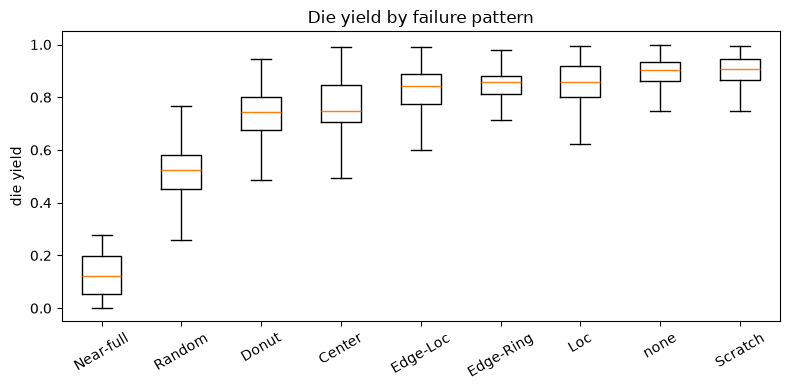

In [11]:
fig = eda.plot_yield_by_type(df)
fig.savefig(FIG_DIR / 'wm811k_yield_by_type.png', dpi=150)

## 5. Train / test split provided by the dataset

In [12]:
lab = df[df['is_labeled']]
pd.crosstab(lab['failure_type'], lab['split'])

split,Test,Training
failure_type,,
Center,832,3462
Donut,146,409
Edge-Loc,2772,2417
Edge-Ring,1126,8554
Loc,1973,1620
Near-full,95,54
Random,257,609
Scratch,693,500
none,110701,36730


## Findings

**Data**
- **811,457 wafers, only 21.3% labeled** (172,950). The 638k unlabeled maps are a candidate for semi-supervised learning later, but step 2 trains on labeled wafers only.
- **Extreme class imbalance:** `none` is 85.2% of labeled wafers. The rarest class, `Near-full`, has just **149 examples, ~990x fewer** than `none`. Accuracy is meaningless here: always predicting `none` already scores 85%.
- **632 distinct map shapes** (most common: 32x29, 25x27, 49x39).

**Defect pattern → yield**

| Pattern | Mean die yield | vs `none` (89.4%) |
|---|---|---|
| Near-full | 12.3% | −77 pts |
| Random | 51.9% | −38 pts |
| Donut | 72.3% | −17 pts |
| Center | 76.8% | −13 pts |
| Edge-Loc | 81.7% | −8 pts |
| Edge-Ring | 84.9% | −5 pts |
| Loc | 85.0% | −4 pts |
| Scratch | 89.9% | ≈ 0 |

- Pattern alone explains a large share of yield loss: `Near-full` and `Random` wafers are effectively scrap, while `Scratch` costs almost nothing in die count. For an engineer, **detecting Random / Donut / Center early matters more than catching every Scratch**, so per-class recall should be weighted by yield impact, not treated equally.
- Even `none` wafers range from 53% to 100% yield, so pattern is not the only driver of loss (motivates the process-side model in step 3).

**The dataset's own train/test split is unusual**
- `Edge-Ring` is 88% training, but `Edge-Loc`, `Loc`, `Near-full` and `Scratch` have *more* test than training wafers, and `none` is 75% test. Class mix differs sharply between the two halves.

**Decisions for step 2**
1. **Metric:** macro-F1 and per-class recall; also report a yield-weighted recall.
2. **Split:** re-split the labeled wafers myself, stratified by class and **grouped by lot**, so wafers from the same lot never sit in both train and test (avoids leakage from lot-level similarity). Keep the original split only as a secondary comparison.
3. **Input:** resize maps to 64x64 with nearest-neighbour interpolation so die states stay discrete (0/1/2).
4. **Imbalance:** class-weighted loss plus rotation/flip augmentation for rare classes (wafer patterns are rotation-invariant, so this is physically valid). Consider downsampling `none`.
